# Problem — rainfall from a communication network


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测到目标核查卡

当前存在 `data/raw_data.npz`；所述获取/估计路径由本地代码实现。

任务 `microwave_link_rainfall_field` 的观测定义：当前raw_data.npz的实际键、形状、dtype与README单位说明：link_records (1, 496180, 11) float64：Complete native records; columns frequency(GHz), UTC timestamp, minimum/maximum power(dBm), path length(km), start longitude/latitude and end longitude/latitude(degrees), numeric link ID(dimensionless), polarization code(dimensionless).；record_valid (1, 496180, 11) uint8：Dimensionless availability mask for link_records;1 means observed,0 means missing. A missing value is stored as zero in link_records and must not be interpreted as a measured zero.；projected_links (1, 2472, 5) float64：Input-only geometry calibration: numeric link ID(dimensionless), projected start easting/northing and end easting/northing(km), for links passing metadata consistency checks.；grid_xy (1, 38063, 2) float64：Required grid positions, projected easting then northing(km); row order defines the output axis.；rain_coefficients (1, 2, 201, 3) float64：Polarization axis horizontal then vertical; columns frequency f(GHz), coefficient a(mm/h multiplied by(km/dB)^b), and exponent b(dimensionless).。恢复目标：38063点daily accumulated rainfall，mm。

获取模型：雨致microwave衰减经path-length归一化及频率/极化power law转为雨强，再空间条件恢复。实际恢复算法：physics_model.retrieve_links/rainfall_from_powers；solvers.interpolate普通kriging，reconstruct汇总96intervals。语义类型为 `inverse_spatial`；其中闭式逆也属于反问题，但内部制造观测或缺输入的限制见下文。

真值情况：数值方法参考，不能当作独立物理真值；test/validation.md:37是完整原始conditional estimate，不是独立雨量测量真值。评估方法参考与仪器校准均不能当作独立物理真值。

现有实验和图：microwave_link_rainfall_field.ipynb单元3有保存图；ax[0,0].add_collection(LineCollection(segments,colors='#126d82',linewidths=.3,alpha=.6,rasterized=True));ax[0,0].autoscale();ax[0,0].set_aspect('equal');ax[0,0].set(title='All nati；microwave_link_rainfall_field.ipynb单元5有保存图；ax[0,0].plot(h,data[sel,2],label='Measured minimum',color='#3b6ba5');ax[0,0].plot(h,data[sel,3],label='Measured maximum',color='#cf8532',alpha=.8);ax[0,0].plot(h,stages['Pref'][sel；microwave_link_rainfall_field.ipynb单元7有保存图；图内容由该单元调用的本地visualization函数生成；microwave_link_rainfall_field.ipynb单元8：Results — transient structure and scientific comparisons；microwave_link_rainfall_field.ipynb单元9有保存图；ax[1,1].plot(hour,mean_intensity,color='#126d82',label='Grid mean');ax[1,1].plot(hour,peak_intensity,color='#af6038',label='Grid maximum');ax[1,1].set(xlabel='Hours since 2011-09-1；microwave_link_rainfall_field.ipynb单元11有保存图；ax[1,2].set(xlabel='Hours since 2011-09-09 08:00 UTC',ylabel='Selected-link rain intensity / mm/h',title='Same observed powers; conditional attenuation correction');ax[1,2].legend(。图/比较代码位于单元1, 3, 5, 7, 9, 11（从0计数）。代码单元6个，带execution_count的6个，保存PNG输出6幅；本审计未重新运行。

现有输出来自历史执行；本次未复跑。

限制与缺口：本次为静态语义与证据核查，未重新验证数值正确性或运行结果。

<!-- inverse-evidence-audit:20261026:end -->


Rain attenuates a microwave signal, but dry-weather propagation and wet antennas also change received powers. We reconstruct the **complete 38,063-point daily rainfall field**, using every native interval in the 48-hour measurement history. This is actual Netherlands communication-network data, with a conditional midpoint/ordinary-kriging estimator, **not independently measured rainfall truth**.

This notebook actively computes the whole benchmark, an independent IDW comparison and physical parameter diagnostics. Original-method arrays are separately labeled comparisons. There is no cache-preview substitution. Six chapters develop the problem, data, physics, method, results and conclusion.


In [1]:
from pathlib import Path
import os,sys,time,json,subprocess,datetime
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from IPython.display import display,Image
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'data/raw_data.npz').exists())
os.chdir(root)
if str(root) not in sys.path:sys.path.insert(0,str(root))
from src.preprocessing import prepare
from src.physics_model import rainfall_from_powers
from src.solvers import reconstruct,midpoint_observations,interpolate,climatological_variogram
from src.visualization import export_figure
plt.rcParams.update({'font.size':10,'axes.titlesize':11,'axes.labelsize':10,'figure.facecolor':'white','axes.spines.top':False,'axes.spines.right':False})
figdir=Path(os.environ.get('IMAGING_FIGURE_DIR','output/notebook_figures'));figdir.mkdir(parents=True,exist_ok=True)
with np.load('data/raw_data.npz',allow_pickle=False) as z:raw={k:z[k].copy() for k in z.files}
with np.load('notebooks/reference_outputs/original_comparisons.npz',allow_pickle=False) as z:original={k:z[k].copy() for k in z.files}
with np.load('notebooks/reference_outputs/original_instantaneous.npz',allow_pickle=False) as z:original_instant=z['rainfall'].copy()
data=prepare(raw);grid=raw['grid_xy'][0];geometry=raw['projected_links'][0]
print({'python':sys.executable,'numpy':np.__version__,'scipy':scipy.__version__,'matplotlib':matplotlib.__version__,'backend':matplotlib.get_backend(),'thread_environment':{k:os.environ.get(k) for k in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS']}})
def save(fig,name,arrays,title):
 path=export_figure(fig,figdir,name,arrays,title);plt.close(fig);display(Image(filename=str(path)))
def map_panel(ax,values,title,*,signed=False,maximum=None):
 bound=max(float(np.max(abs(values))),1e-16) if maximum is None else maximum
 artist=ax.scatter(grid[:,0],grid[:,1],c=values,s=1.5,marker='s',linewidths=0,rasterized=True,cmap='RdBu_r' if signed else 'viridis',vmin=-bound if signed else 0,vmax=bound)
 ax.set(title=title,xlabel='Easting / km',ylabel='Northing / km');ax.set_aspect('equal');return artist


{'python': 'D:\\yan1\\agent\\AutoSkill\\imaging-101-maintainer\\research-runtime\\Scripts\\python.exe', 'numpy': '2.4.6', 'scipy': '1.17.1', 'matplotlib': '3.11.1', 'backend': 'Agg', 'thread_environment': {'OMP_NUM_THREADS': '1', 'OPENBLAS_NUM_THREADS': '1', 'MKL_NUM_THREADS': '1'}}


## Data — all observations and native spatial support

The public data contain 496,180 native records and an explicit missing-value mask. Input-only frequency, repeated-time and changing-metadata checks retain 465,514 records from 2,472 link IDs over 192 interval ends. Opposite directions can share a physical path. Unknown polarization is explicitly assigned the vertical calibration; no hidden target supplies this assumption.

The network reports 15-minute extrema of 10 Hz power measurements, with 1 dB quantization. Projected coordinates are known geometric calibration in EPSG 28992, expressed in km. The full target grid is retained, including places far from an active link. Histograms and coverage below use the actual valid observations.


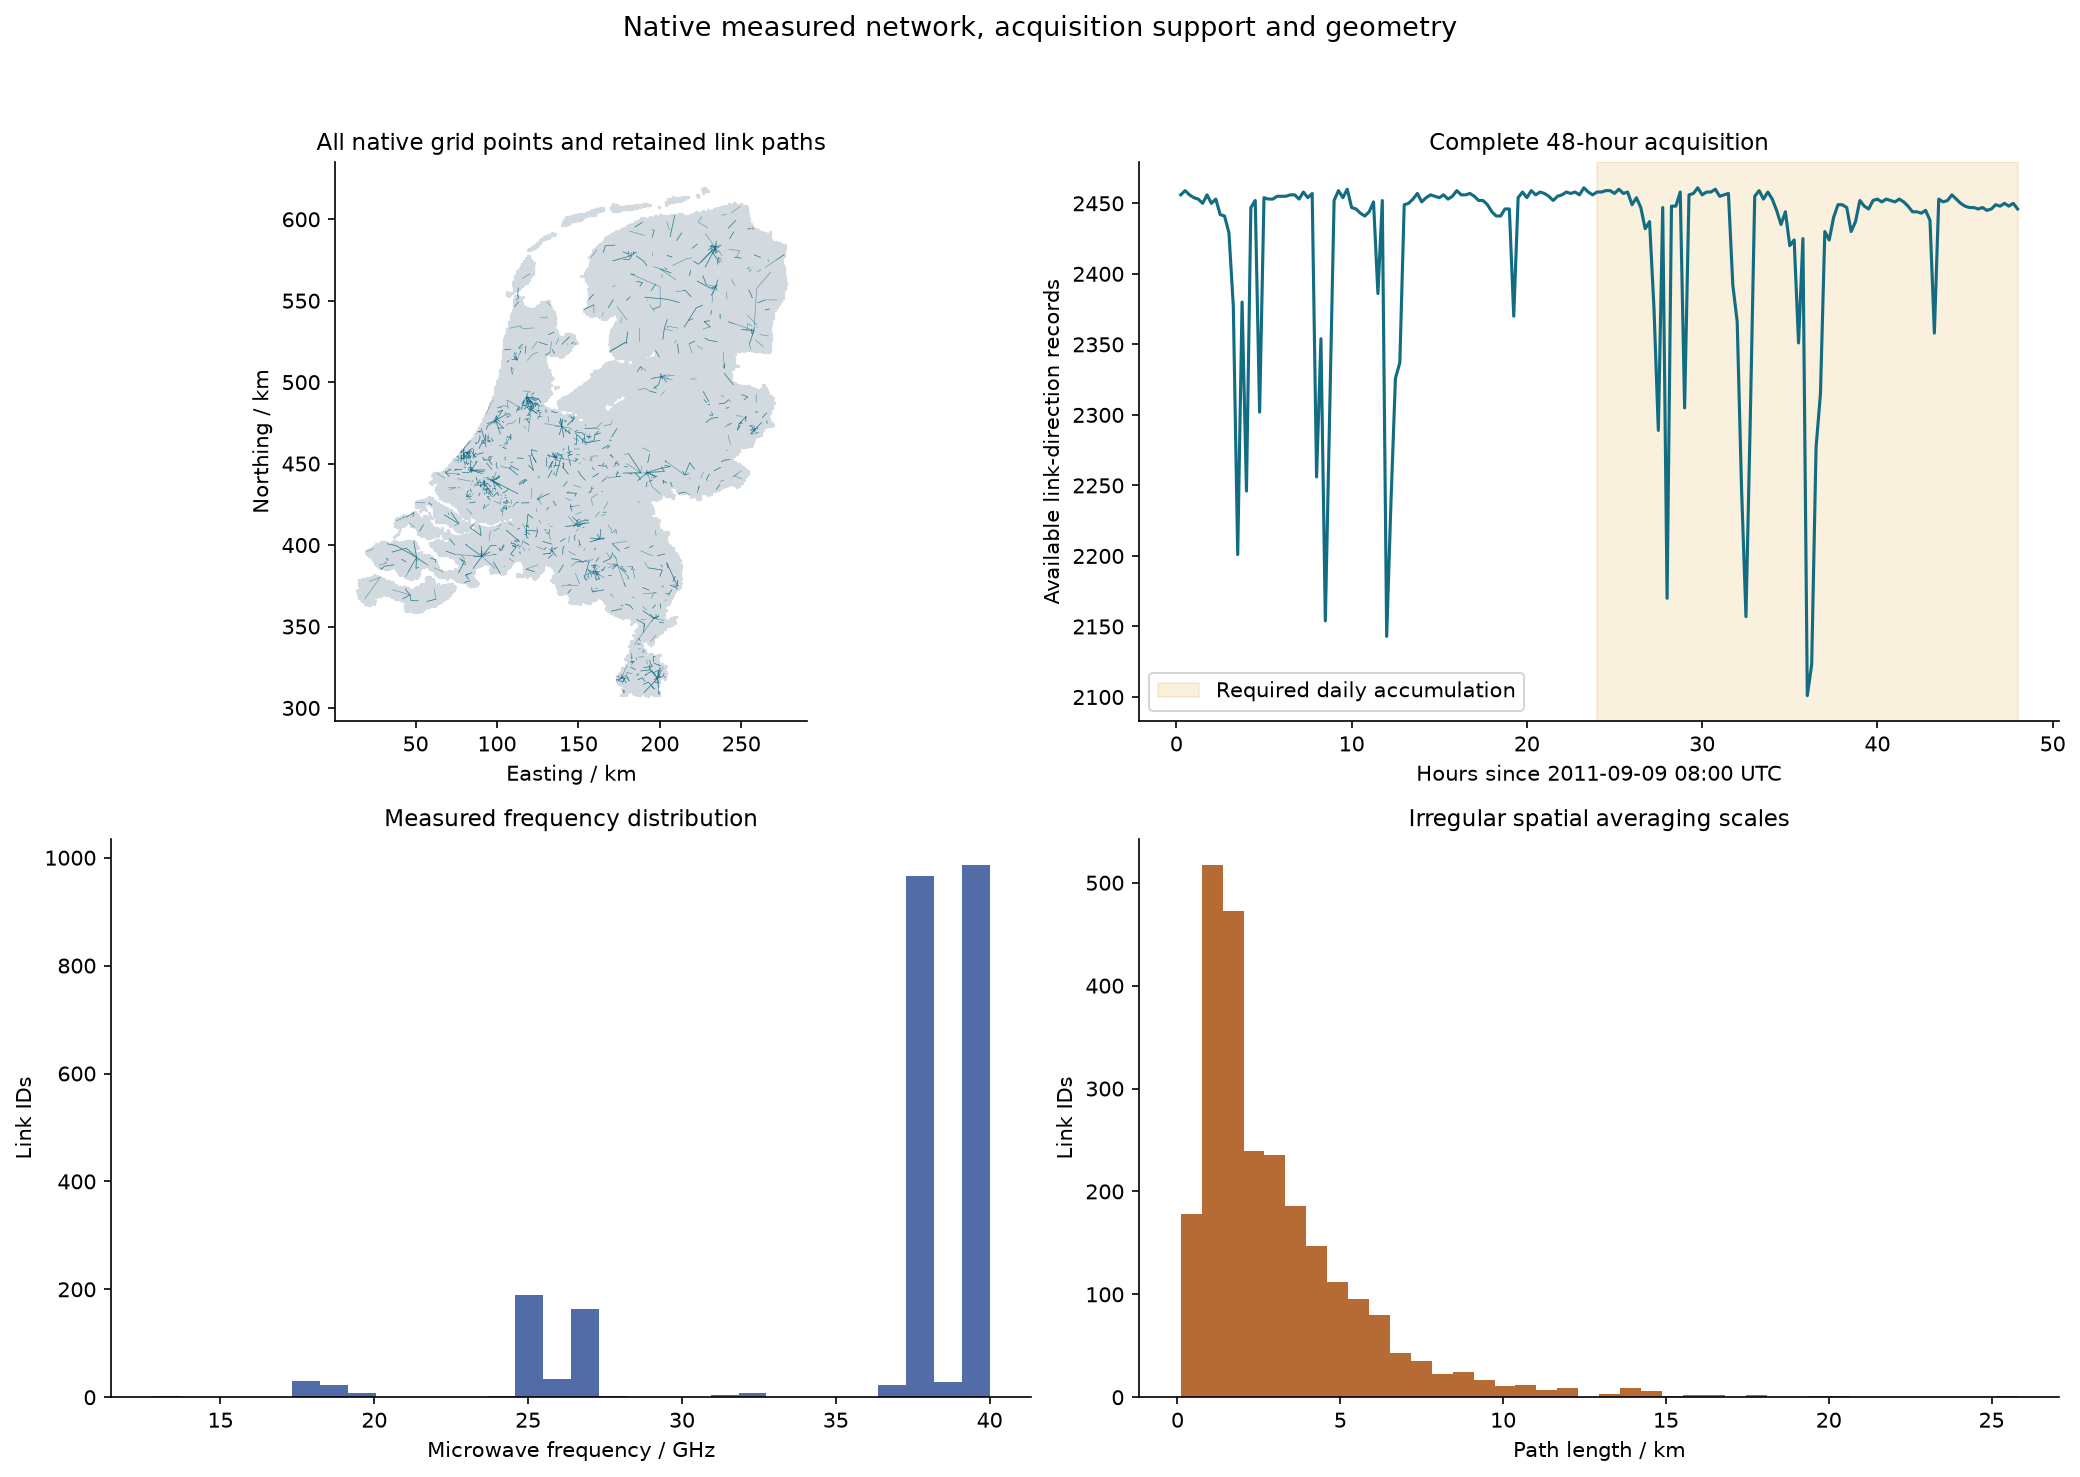

In [2]:
fig,ax=plt.subplots(2,2,figsize=(14,10))
segments=geometry[:,1:].reshape(-1,2,2)
ax[0,0].scatter(grid[:,0],grid[:,1],s=.4,c='#d2d9df',rasterized=True)
ax[0,0].add_collection(LineCollection(segments,colors='#126d82',linewidths=.3,alpha=.6,rasterized=True));ax[0,0].autoscale();ax[0,0].set_aspect('equal');ax[0,0].set(title='All native grid points and retained link paths',xlabel='Easting / km',ylabel='Northing / km')
times,counts=np.unique(data[:,1],return_counts=True);hours=np.arange(len(times))*.25+.25
ax[0,1].plot(hours,counts,color='#126d82');ax[0,1].axvspan(24,48,color='#e4b14b',alpha=.18,label='Required daily accumulation');ax[0,1].set(xlabel='Hours since 2011-09-09 08:00 UTC',ylabel='Available link-direction records',title='Complete 48-hour acquisition');ax[0,1].legend()
_,first=np.unique(data[:,9],return_index=True)
ax[1,0].hist(data[first,0],bins=30,color='#526ca8');ax[1,0].set(xlabel='Microwave frequency / GHz',ylabel='Link IDs',title='Measured frequency distribution')
ax[1,1].hist(data[first,4],bins=40,color='#b66b35');ax[1,1].set(xlabel='Path length / km',ylabel='Link IDs',title='Irregular spatial averaging scales')
save(fig,'figure1_network',dict(grid_xy=grid,projected_links=geometry,timestamps=times,records_per_interval=counts,frequency_GHz=data[first,0],length_km=data[first,4]),'Native measured network, acquisition support and geometry')


## Physics — infer attenuation before rainfall

Let P0 be the rolling dry-weather reference power, PminC and PmaxC the corrected extrema, and L the path length in km. Effective attenuation in dB yields mean rain intensity R in mm/h:

$$A_{max}=P_0-P_{min}^{C},\qquad A_{min}=P_0-P_{max}^{C},$$
$$R=(1-\alpha)a\left[\frac{\max(A_{min}-A_a,0)}L\right]^b+\alpha a\left[\frac{\max(A_{max}-A_a,0)}L\right]^b.$$

Here a,b are the independently supplied frequency/polarization coefficients, Aa=2.3 dB is an effective antenna correction and alpha=0.33 weights maximum-intensity contributions. Dry-reference estimation uses a preceding 24-hour window with at least 2.5 dry hours. The preceding-neighborhood wet/dry calculation requires six valid hours; unavailable early retrievals are not interpreted as zero rain. These empirical corrections remain model assumptions.

The next cell performs the **full fresh reconstruction**, including every one of the 96 target intervals. The demonstration link is chosen only from complete measured histories by its observed power range; it does not select or mask the reconstruction support.


{'fresh_full_runtime_seconds': 761.162954600004, 'judge': {'status': 'pass', 'passed': True, 'metrics': {'nrmse': 8.309475243871377e-15, 'negative_count': 0}, 'thresholds': {'nrmse': {'comparison': '<=', 'boundary': 9.663465651076436e-09}, 'negative_count': {'comparison': '<=', 'boundary': 0}}, 'errors': []}}


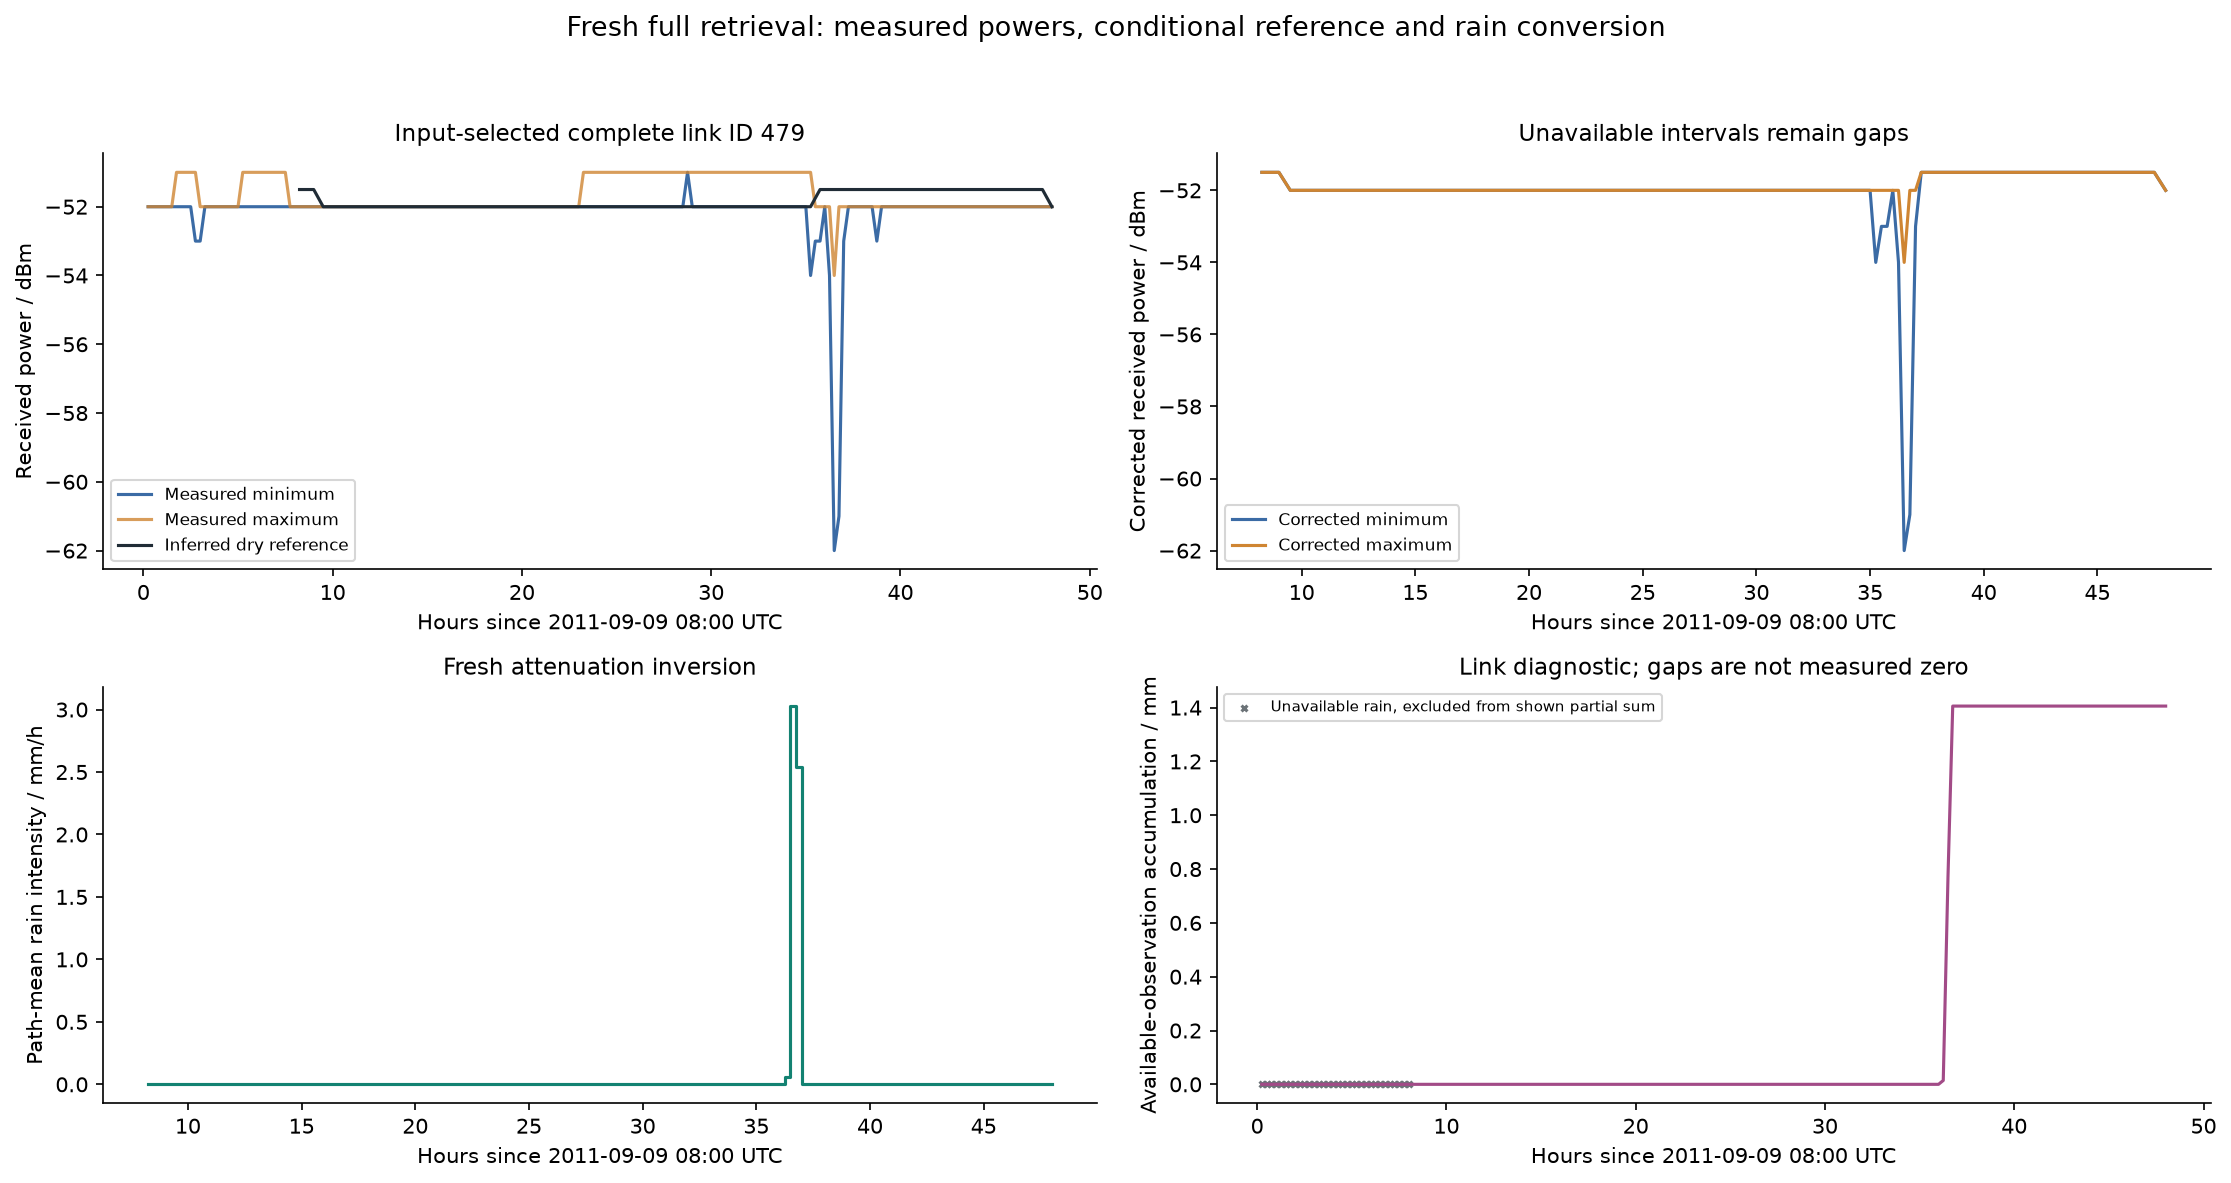

In [3]:
start=time.perf_counter()
fresh=reconstruct(raw,retain_fields=True)
reconstruction=fresh['reconstruction'];stages=fresh['stages'];data=fresh['data'];runtime=time.perf_counter()-start
Path('output').mkdir(exist_ok=True);np.savez_compressed('output/reconstruction.npz',reconstruction=reconstruction)
evaluation=subprocess.run([sys.executable,'evaluation/judge.py','--prediction','output/reconstruction.npz','--report','output/judge_report.json'],capture_output=True,text=True,check=True)
report=json.loads(Path('output/judge_report.json').read_text());print({'fresh_full_runtime_seconds':runtime,'judge':report})
ids,nrecords=np.unique(data[:,9],return_counts=True);full=ids[nrecords==192]
link=max(full,key=lambda u:np.ptp(data[data[:,9]==u,2]));sel=np.flatnonzero(data[:,9]==link);h=np.arange(192)*.25+.25
fig,ax=plt.subplots(2,2,figsize=(15,8))
ax[0,0].plot(h,data[sel,2],label='Measured minimum',color='#3b6ba5');ax[0,0].plot(h,data[sel,3],label='Measured maximum',color='#cf8532',alpha=.8);ax[0,0].plot(h,stages['Pref'][sel],label='Inferred dry reference',color='#202c36',lw=1.5);ax[0,0].set(ylabel='Received power / dBm',title=f'Input-selected complete link ID {int(link)}');ax[0,0].legend(fontsize=8)
ax[0,1].plot(h,stages['PminCor'][sel],label='Corrected minimum',color='#3b6ba5');ax[0,1].plot(h,stages['PmaxCor'][sel],label='Corrected maximum',color='#cf8532');ax[0,1].set(ylabel='Corrected received power / dBm',title='Unavailable intervals remain gaps');ax[0,1].legend(fontsize=8)
ax[1,0].step(h,stages['Rmean'][sel],where='post',color='#138272');ax[1,0].set(ylabel='Path-mean rain intensity / mm/h',title='Fresh attenuation inversion')
rain=stages['Rmean'][sel];available=np.isfinite(rain);accum=np.cumsum(np.where(available,rain,0))*.25
ax[1,1].plot(h,accum,color='#a24b87');ax[1,1].scatter(h[~available],np.zeros(np.sum(~available)),marker='x',s=8,color='#6c7378',label='Unavailable rain, excluded from shown partial sum');ax[1,1].set(ylabel='Available-observation accumulation / mm',title='Link diagnostic; gaps are not measured zero');ax[1,1].legend(fontsize=7)
for a in ax.ravel():a.set_xlabel('Hours since 2011-09-09 08:00 UTC')
save(fig,'figure2_attenuation',dict(link_id=np.array(link),hours=h,power_min=data[sel,2],power_max=data[sel,3],**{k:v[sel] for k,v in stages.items()},partial_accumulation_mm=accum),'Fresh full retrieval: measured powers, conditional reference and rain conversion')


## Method — conditional spatial recovery

Each path-average intensity is assigned to the projected link midpoint; coincident midpoints are averaged. This is the original point approximation, not a claimed exact line-integral inversion. Ordinary kriging uses 50 nearby midpoint observations, a climatological spherical semivariogram gamma and unit-sum weights:

$$\begin{bmatrix}\Gamma&\mathbf1\\\mathbf1^T&0\end{bmatrix}\begin{bmatrix}w\\\lambda\end{bmatrix}=\begin{bmatrix}g\\1\end{bmatrix},\qquad \Gamma_{ij}=\gamma(\|x_i-x_j\|),\quad g_i=\gamma(\|x_i-q\|).$$

Here x are observation positions, q is a query position, w are weights, lambda is the unknown-mean multiplier and the vector1 contains ones. The estimate is max(0,sum of weights times observed intensity); negative predictions are clipped by the selected original method. The variogram uses a gauge-derived seasonal range, partial sill and nugget, changes at midnight and assumes stationarity and isotropy. The daily field is the sum of all 96 nonnegative interval intensities times 0.25 h.

The comparison reference below is this task's **actual qualified original run**, not independently known rainfall. Two complete independent original runs agreed exactly; the nonzero evaluation tolerance was fixed from measured legitimate float32 output serialization before extraction. The two header-reading adaptations retain every original coefficient; consistent wet/dry option selection is disclosed in validation. Original-script no-wet/dry and IDW runs remain distinct comparisons.


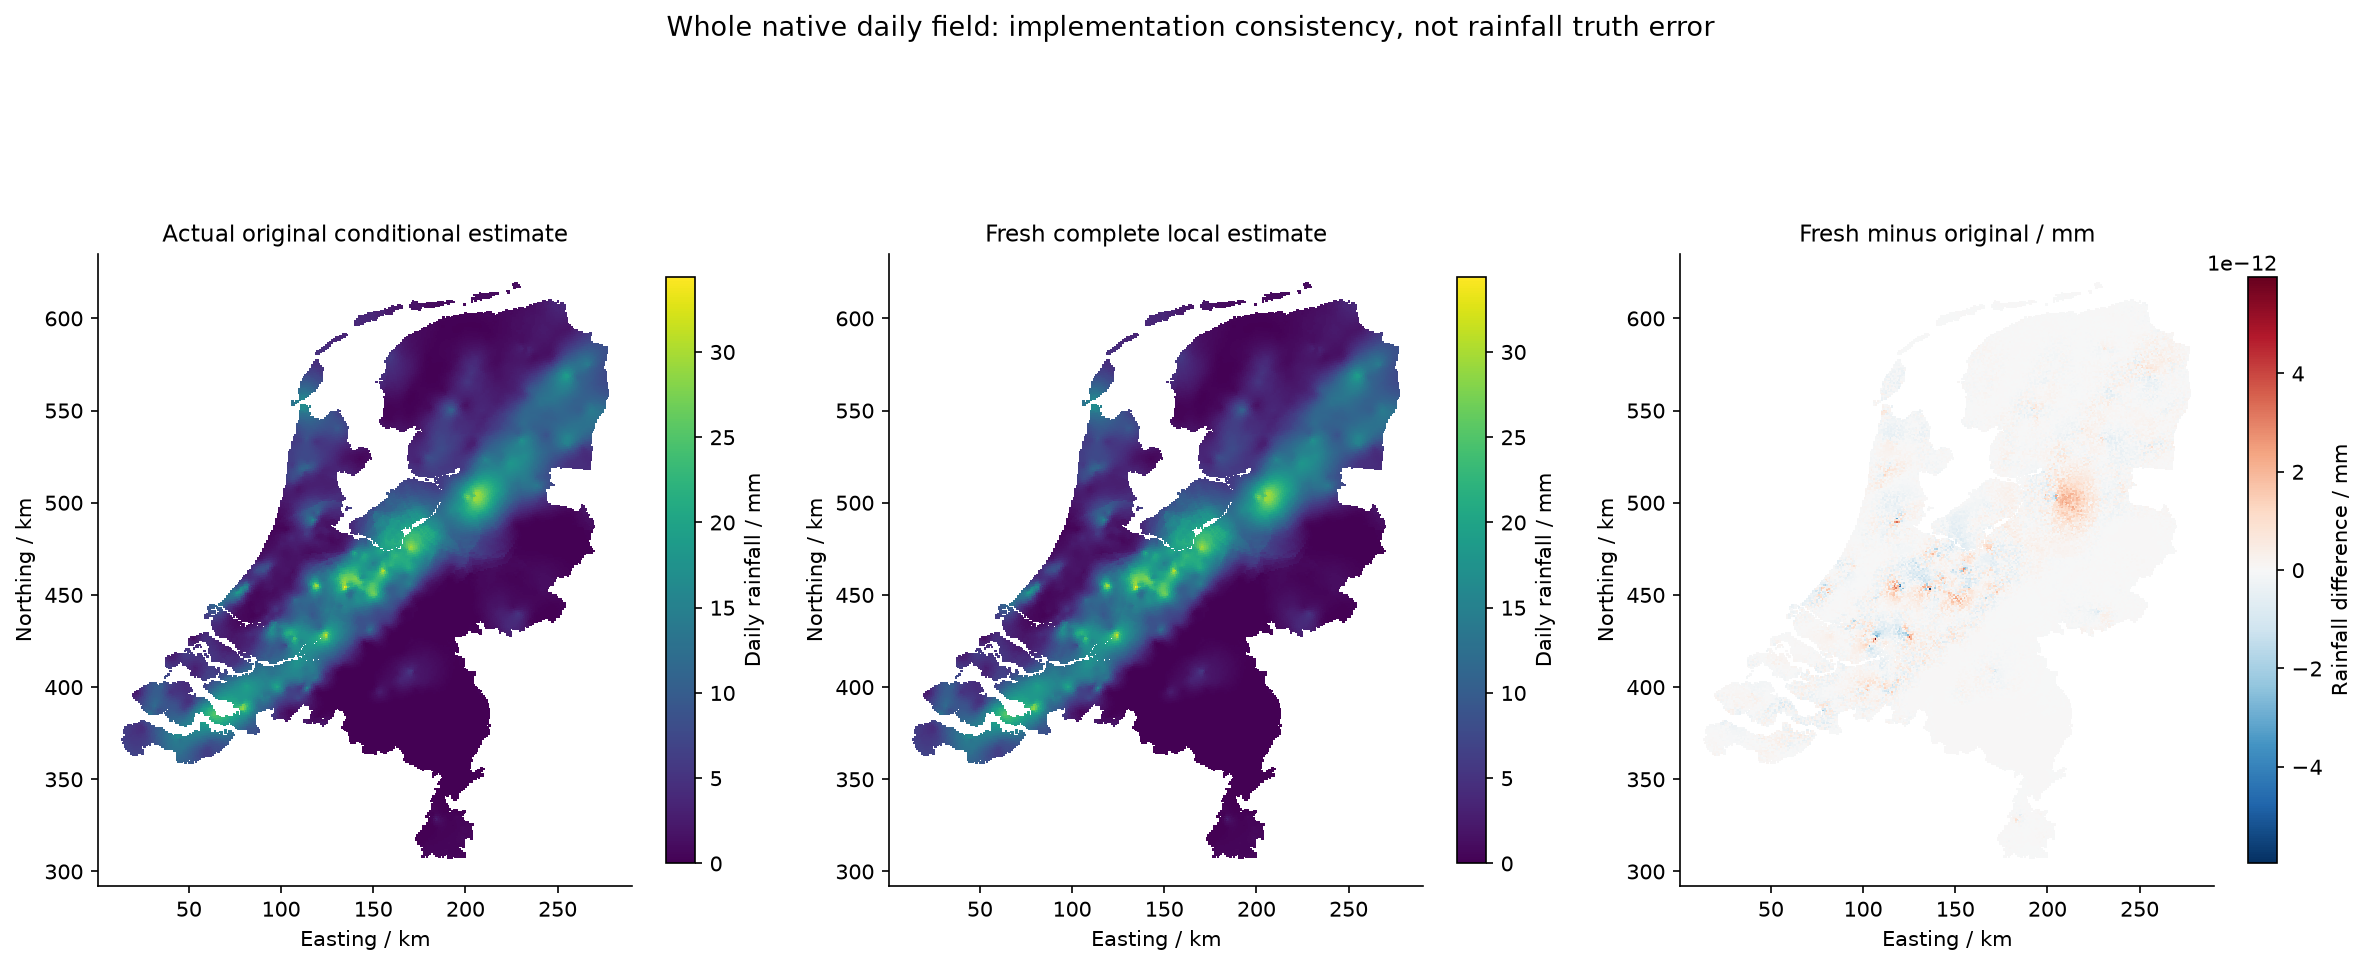

{'full_field_metrics': {'nrmse': 8.309475243871377e-15, 'negative_count': 0}, 'maximum_difference_mm': 5.965006266706041e-12, 'reference_role': 'original conditional method result, not independent truth'}


In [4]:
y=original['original'][0];x=reconstruction[0];difference=x-y
fig,ax=plt.subplots(1,3,figsize=(16,7));bound=max(x.max(),y.max())
for a,values,title,signed in zip(ax,[y,x,difference],['Actual original conditional estimate','Fresh complete local estimate','Fresh minus original / mm'],[False,False,True]):
 artist=map_panel(a,values,title,signed=signed,maximum=None if signed else bound);fig.colorbar(artist,ax=a,shrink=.65,label='Rainfall difference / mm' if signed else 'Daily rainfall / mm')
save(fig,'figure3_daily_field',dict(grid_xy=grid,original_mm=y,fresh_mm=x,difference_mm=difference,nrmse=np.array(report['metrics']['nrmse'])),'Whole native daily field: implementation consistency, not rainfall truth error')
print({'full_field_metrics':report['metrics'],'maximum_difference_mm':float(abs(difference).max()),'reference_role':'original conditional method result, not independent truth'})


## Results — transient structure and scientific comparisons

The first panels compare the full-grid 20:45 UTC intensity map with the actual original output at the same time, and show temporal evolution of the complete daily accumulation. Maps use every native grid point; display color differences are not evaluation masks. The published example also shows radar comparisons, but no independent radar arrays are supplied with this exact repository data, so its paper radar scores are not presented as measurements from this run.

The second figure retains both selected interpolation families and the original no-wet/dry option. IDW is computed afresh on the same observations. The no-wet/dry field is explicitly the successful original script's result; it is not relabeled as a new local run. Different scales are labeled where that original option produces much larger accumulations. These comparisons show dependence on assumptions, not independently established superiority in rainfall accuracy.


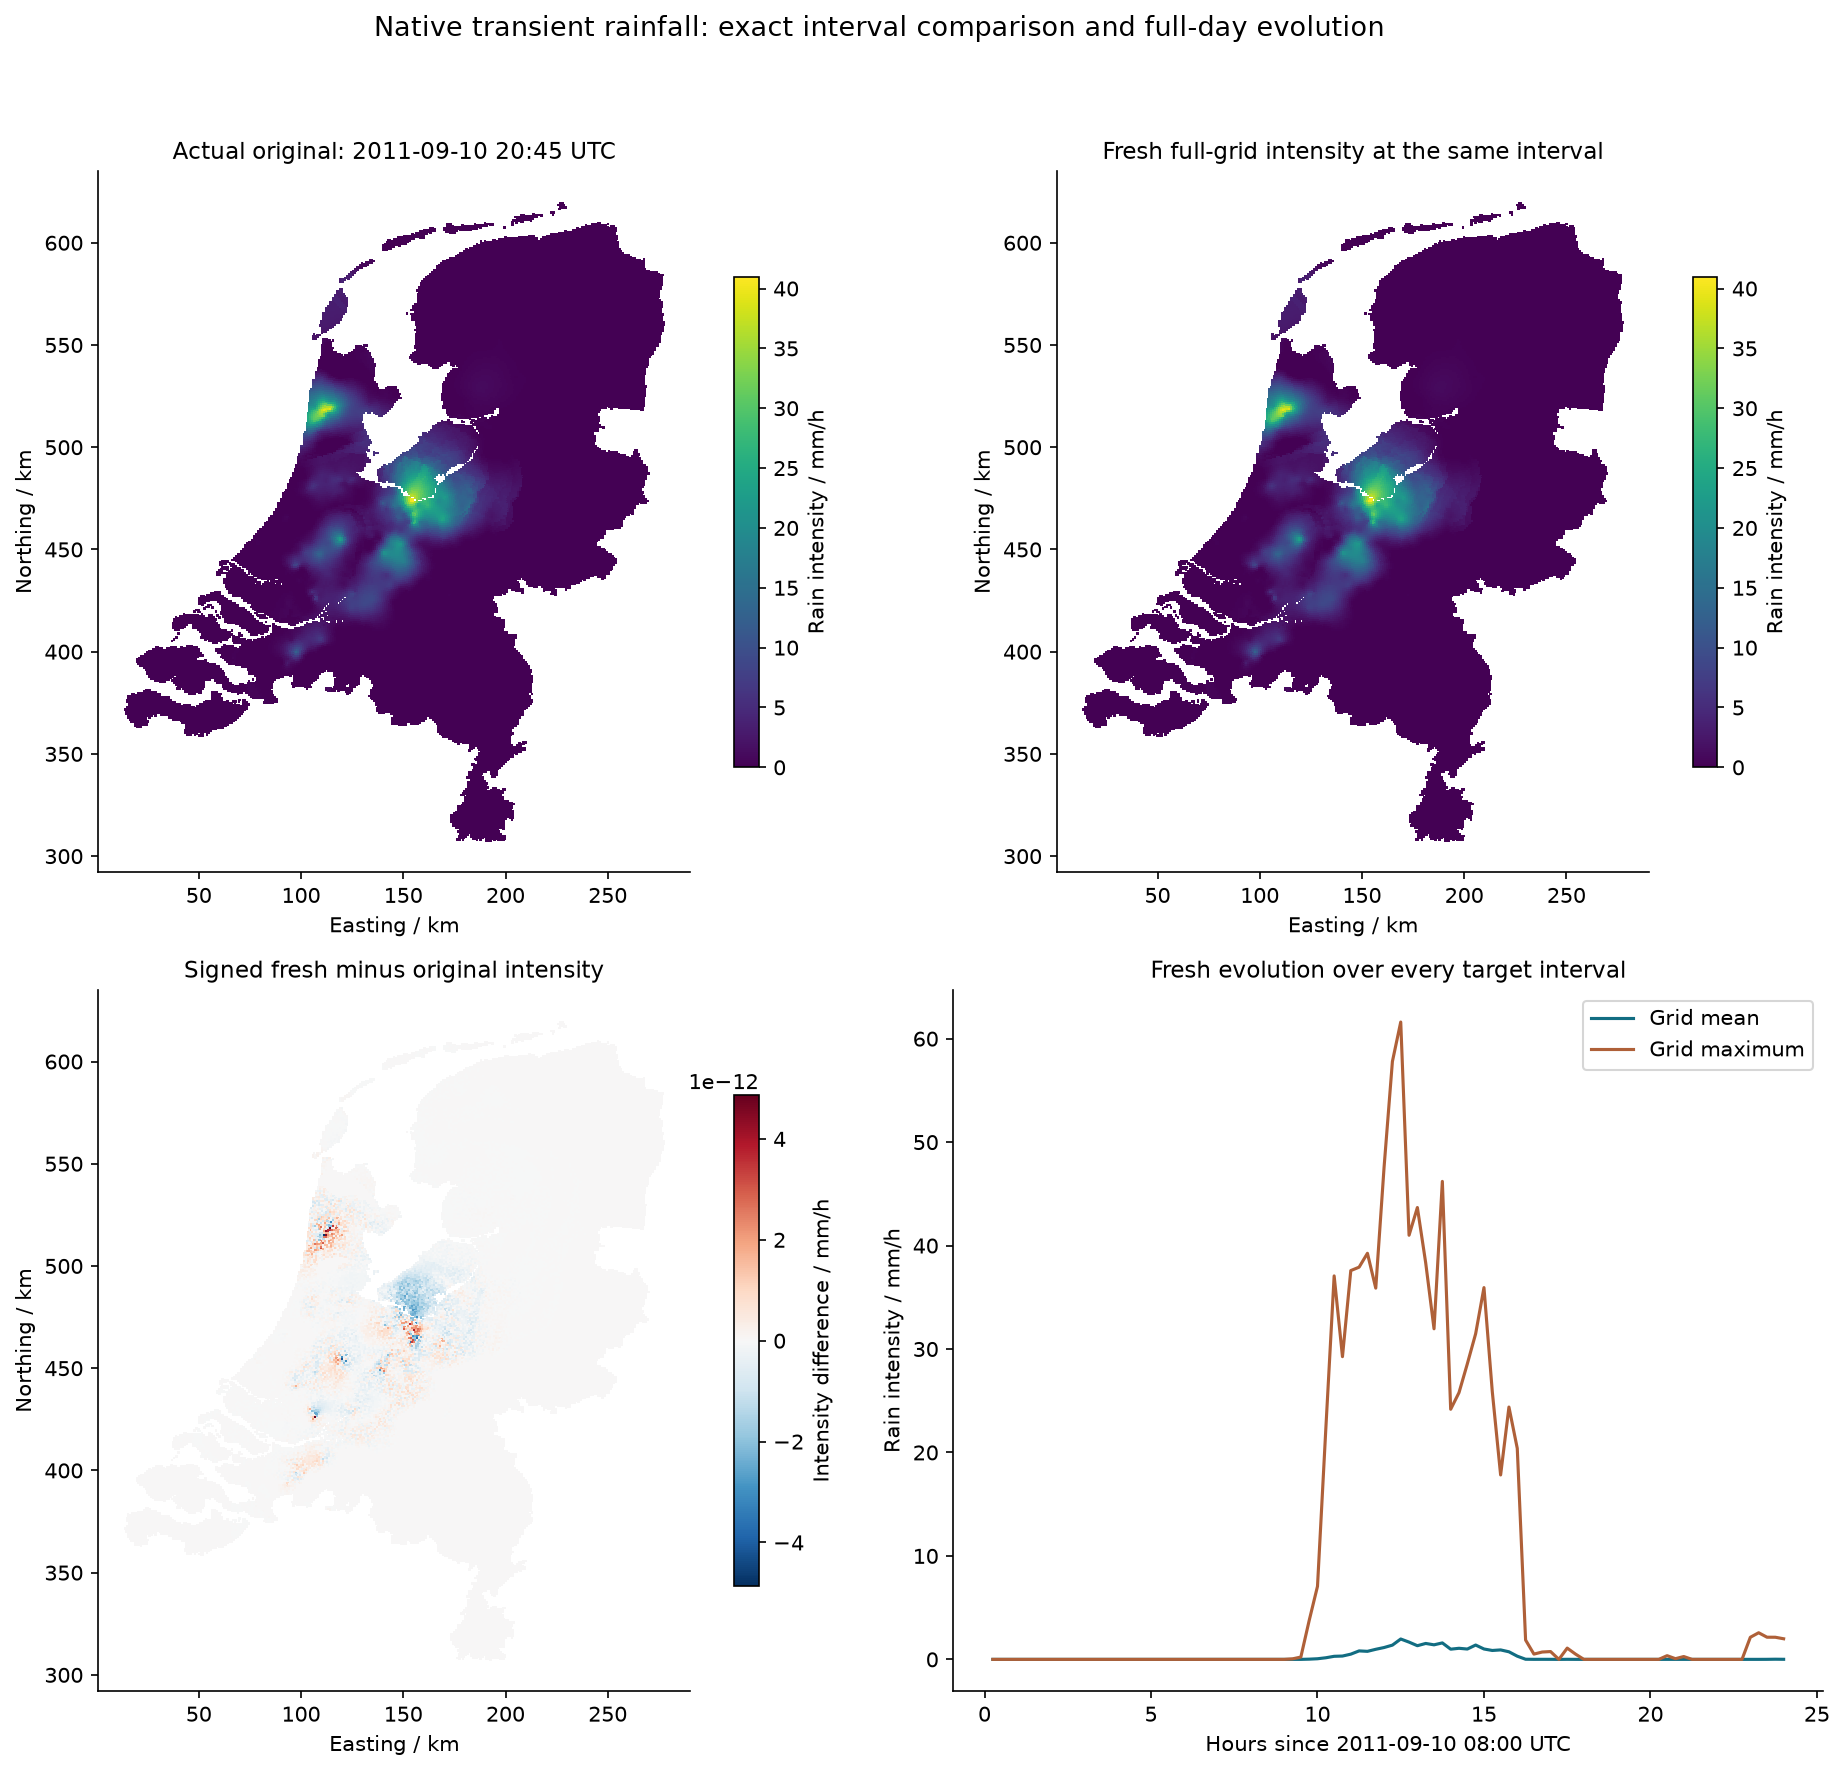

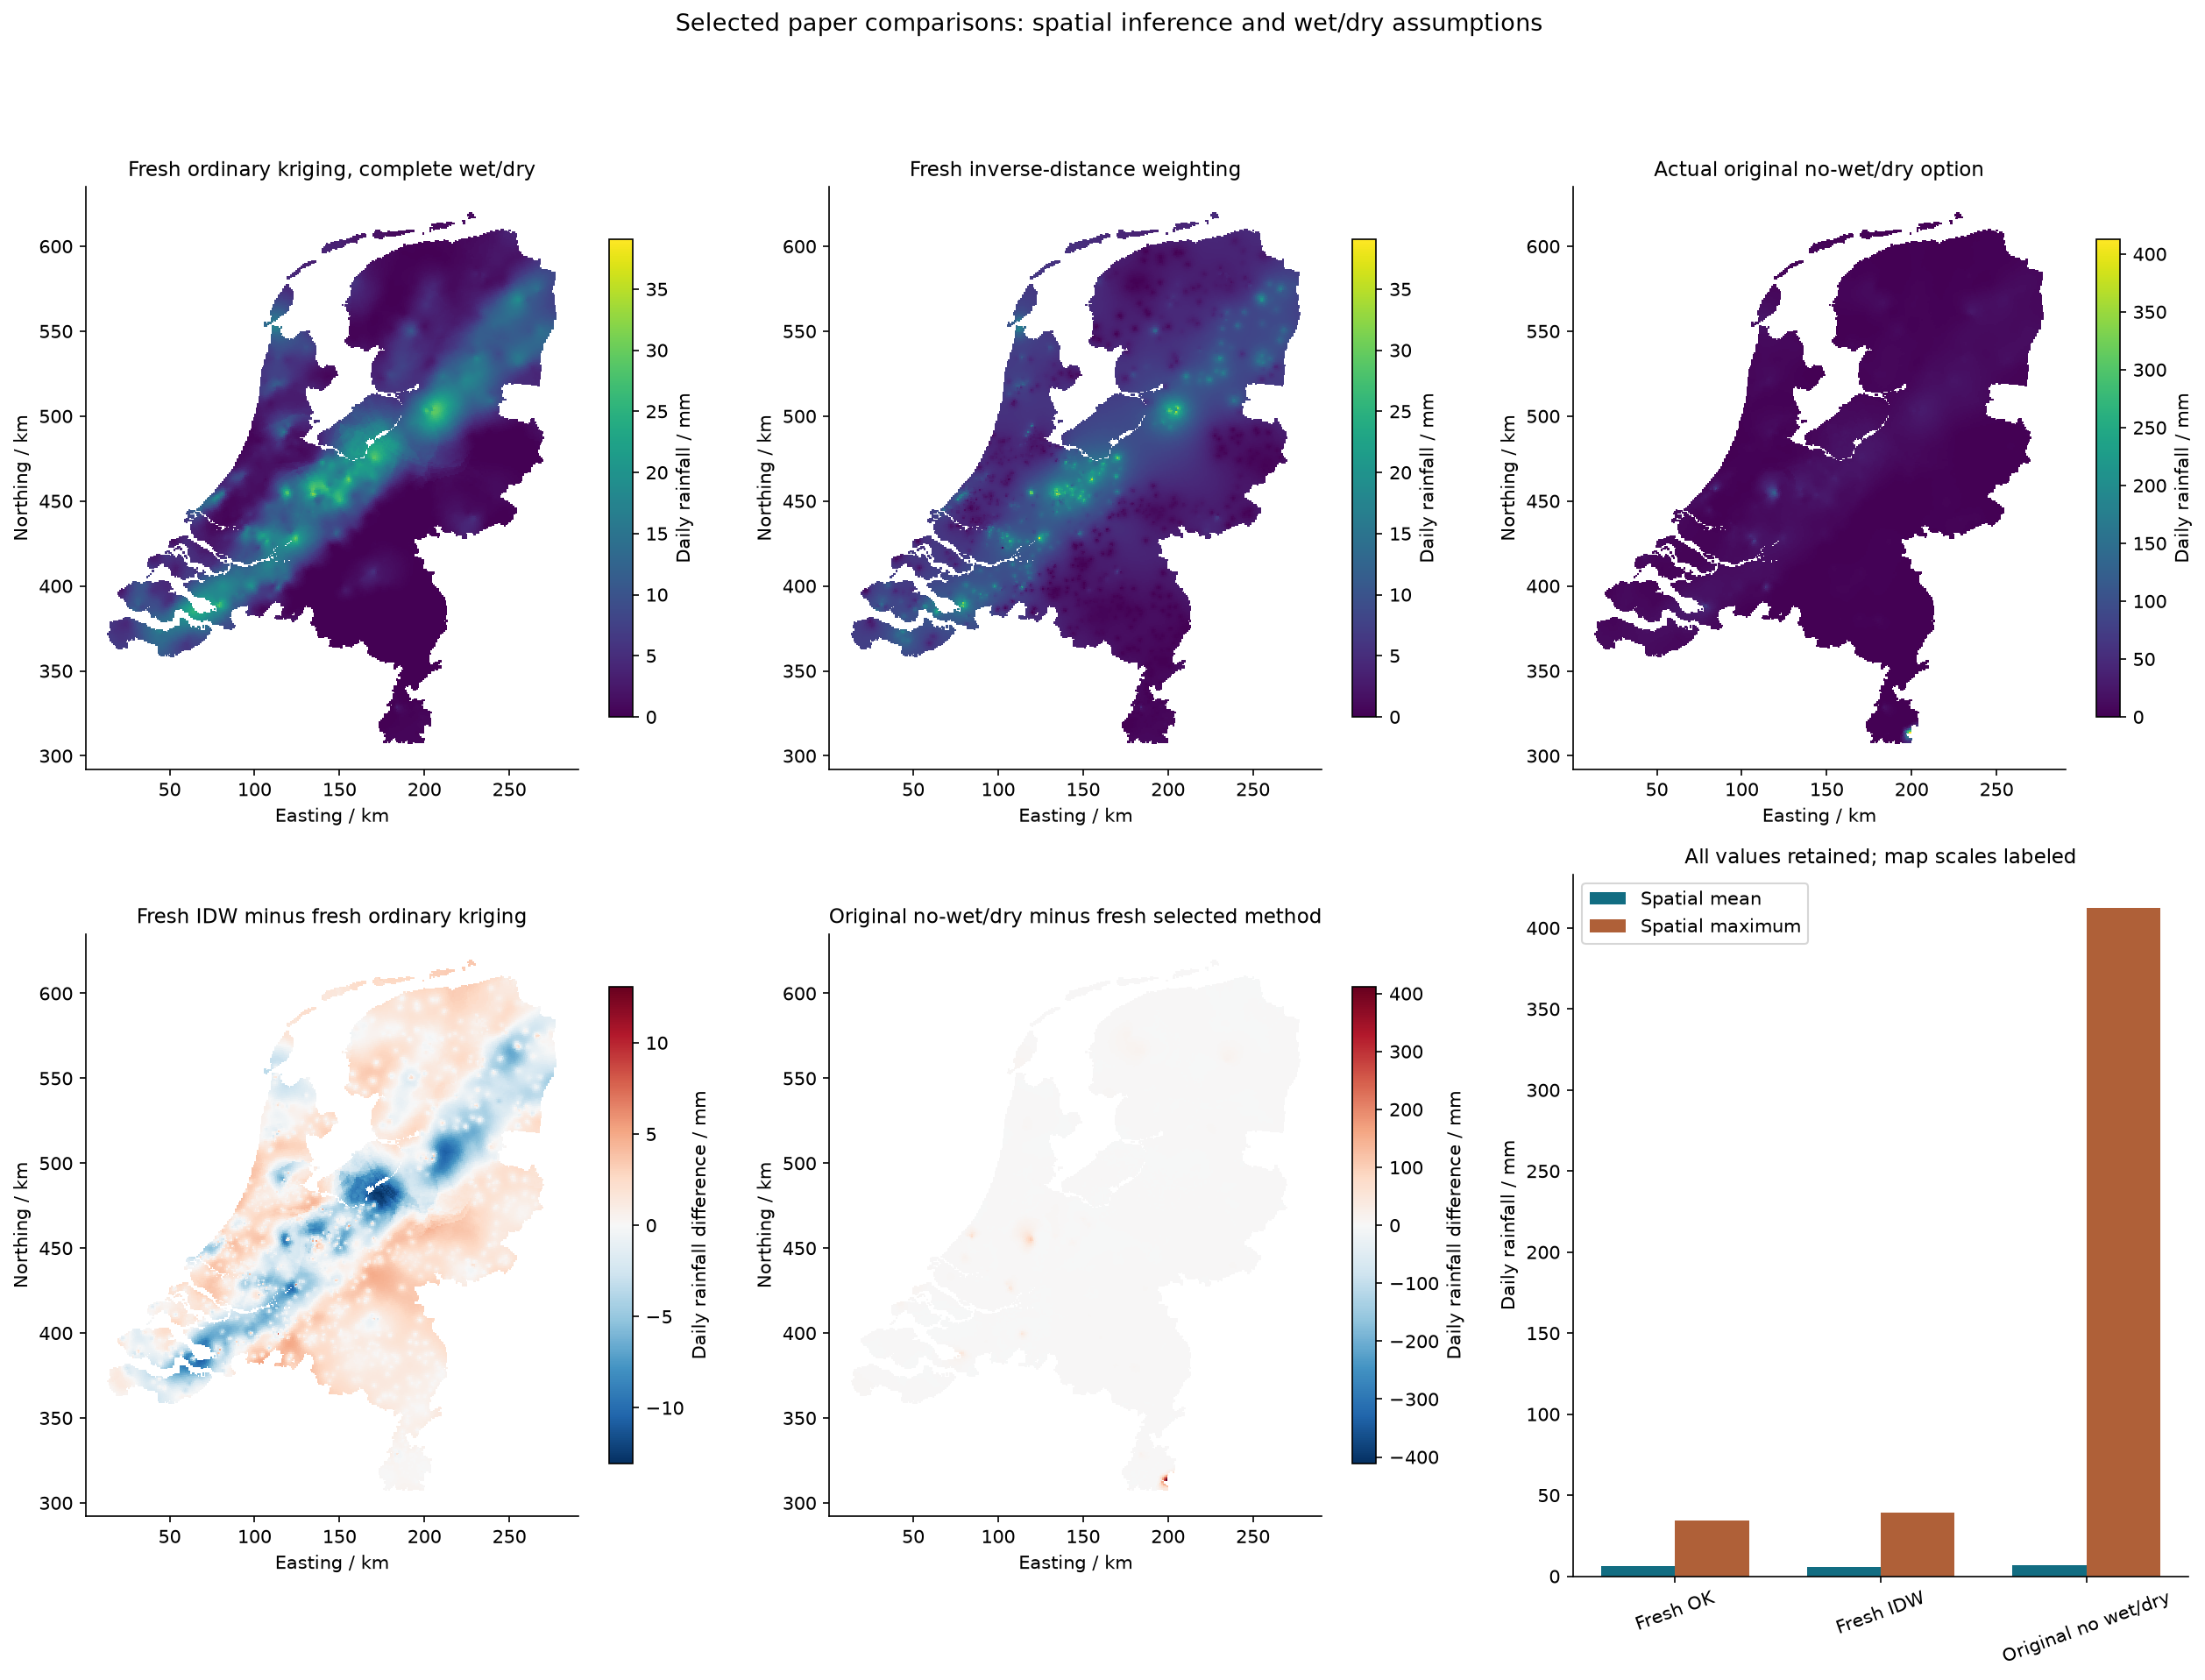

{'fresh_IDW_runtime_seconds': 237.47664159999113, 'fresh_IDW_vs_actual_original_IDW_maxabs_mm': 2.4069635173873394e-11}


In [5]:
stamp=201109102045;frame=int(np.flatnonzero(fresh['timestamps']==stamp)[0]);instant=fresh['fields'][frame]
fig,ax=plt.subplots(2,2,figsize=(13,12));vmax=max(instant.max(),original_instant.max())
for a,v,title in [(ax[0,0],original_instant,'Actual original: 2011-09-10 20:45 UTC'),(ax[0,1],instant,'Fresh full-grid intensity at the same interval')]:
 artist=map_panel(a,v,title,maximum=vmax);fig.colorbar(artist,ax=a,shrink=.7,label='Rain intensity / mm/h')
artist=map_panel(ax[1,0],instant-original_instant,'Signed fresh minus original intensity',signed=True);fig.colorbar(artist,ax=ax[1,0],shrink=.7,label='Intensity difference / mm/h')
mean_intensity=fresh['fields'].mean(axis=1);peak_intensity=fresh['fields'].max(axis=1);hour=(np.arange(96)+1)*.25
ax[1,1].plot(hour,mean_intensity,color='#126d82',label='Grid mean');ax[1,1].plot(hour,peak_intensity,color='#af6038',label='Grid maximum');ax[1,1].set(xlabel='Hours since 2011-09-10 08:00 UTC',ylabel='Rain intensity / mm/h',title='Fresh evolution over every target interval');ax[1,1].legend()
save(fig,'figure4_transient',dict(grid_xy=grid,original_mm_h=original_instant,fresh_mm_h=instant,hours=hour,grid_mean_mm_h=mean_intensity,grid_max_mm_h=peak_intensity),'Native transient rainfall: exact interval comparison and full-day evolution')
start=time.perf_counter();fresh_idw=reconstruct(raw,method='IDW');idw_seconds=time.perf_counter()-start;idw=fresh_idw['reconstruction'][0];no_dry=original['original_no_wet_dry'][0]
fig,ax=plt.subplots(2,3,figsize=(17,13))
for a,v,title in zip(ax[0],[x,idw,no_dry],['Fresh ordinary kriging, complete wet/dry','Fresh inverse-distance weighting','Actual original no-wet/dry option']):
 artist=map_panel(a,v,title,maximum=max(x.max(),idw.max()) if a is not ax[0,2] else no_dry.max());fig.colorbar(artist,ax=a,shrink=.68,label='Daily rainfall / mm')
for a,v,title in [(ax[1,0],idw-x,'Fresh IDW minus fresh ordinary kriging'),(ax[1,1],no_dry-x,'Original no-wet/dry minus fresh selected method')]:
 artist=map_panel(a,v,title,signed=True);fig.colorbar(artist,ax=a,shrink=.68,label='Daily rainfall difference / mm')
names=['Fresh OK','Fresh IDW','Original no wet/dry'];means=[v.mean() for v in [x,idw,no_dry]];maxima=[v.max() for v in [x,idw,no_dry]];index=np.arange(3)
ax[1,2].bar(index-.18,means,width=.36,label='Spatial mean',color='#126d82');ax[1,2].bar(index+.18,maxima,width=.36,label='Spatial maximum',color='#af6038');ax[1,2].set(xticks=index,xticklabels=names,ylabel='Daily rainfall / mm',title='All values retained; map scales labeled');ax[1,2].tick_params(axis='x',labelrotation=20);ax[1,2].legend()
save(fig,'figure5_comparisons',dict(grid_xy=grid,fresh_OK_mm=x,fresh_IDW_mm=idw,original_IDW_mm=original['original_idw'][0],original_no_wet_dry_mm=no_dry,means_mm=np.array(means),maxima_mm=np.array(maxima)),'Selected paper comparisons: spatial inference and wet/dry assumptions')
print({'fresh_IDW_runtime_seconds':idw_seconds,'fresh_IDW_vs_actual_original_IDW_maxabs_mm':float(abs(idw-original['original_idw'][0]).max())})


## Conclusion — reproducibility and conditional uncertainty

The selected whole-field method is reproducible, but accurate code agreement is not a measurement of true rainfall error. Missing histories, unknown polarization, link-midpoint representation, independently calibrated effective antenna losses and a stationary gauge-climatology covariance all limit interpretation. The no-wet/dry comparison and IDW differences expose consequential modeling choices.

The final experiment changes the effective antenna correction to 1.3, 2.3 and 3.3 dB while retaining every measured power and the same inferred reference. It actively recomputes nonlinear link intensities and complete spatial maps at **20:45 UTC**, not alternative daily fields. The signed maps show full-grid instantaneous sensitivity. No new noisy/synthetic observations are generated. Source-supplied reference results, fresh reconstructions and parameter diagnostics remain explicitly distinct.


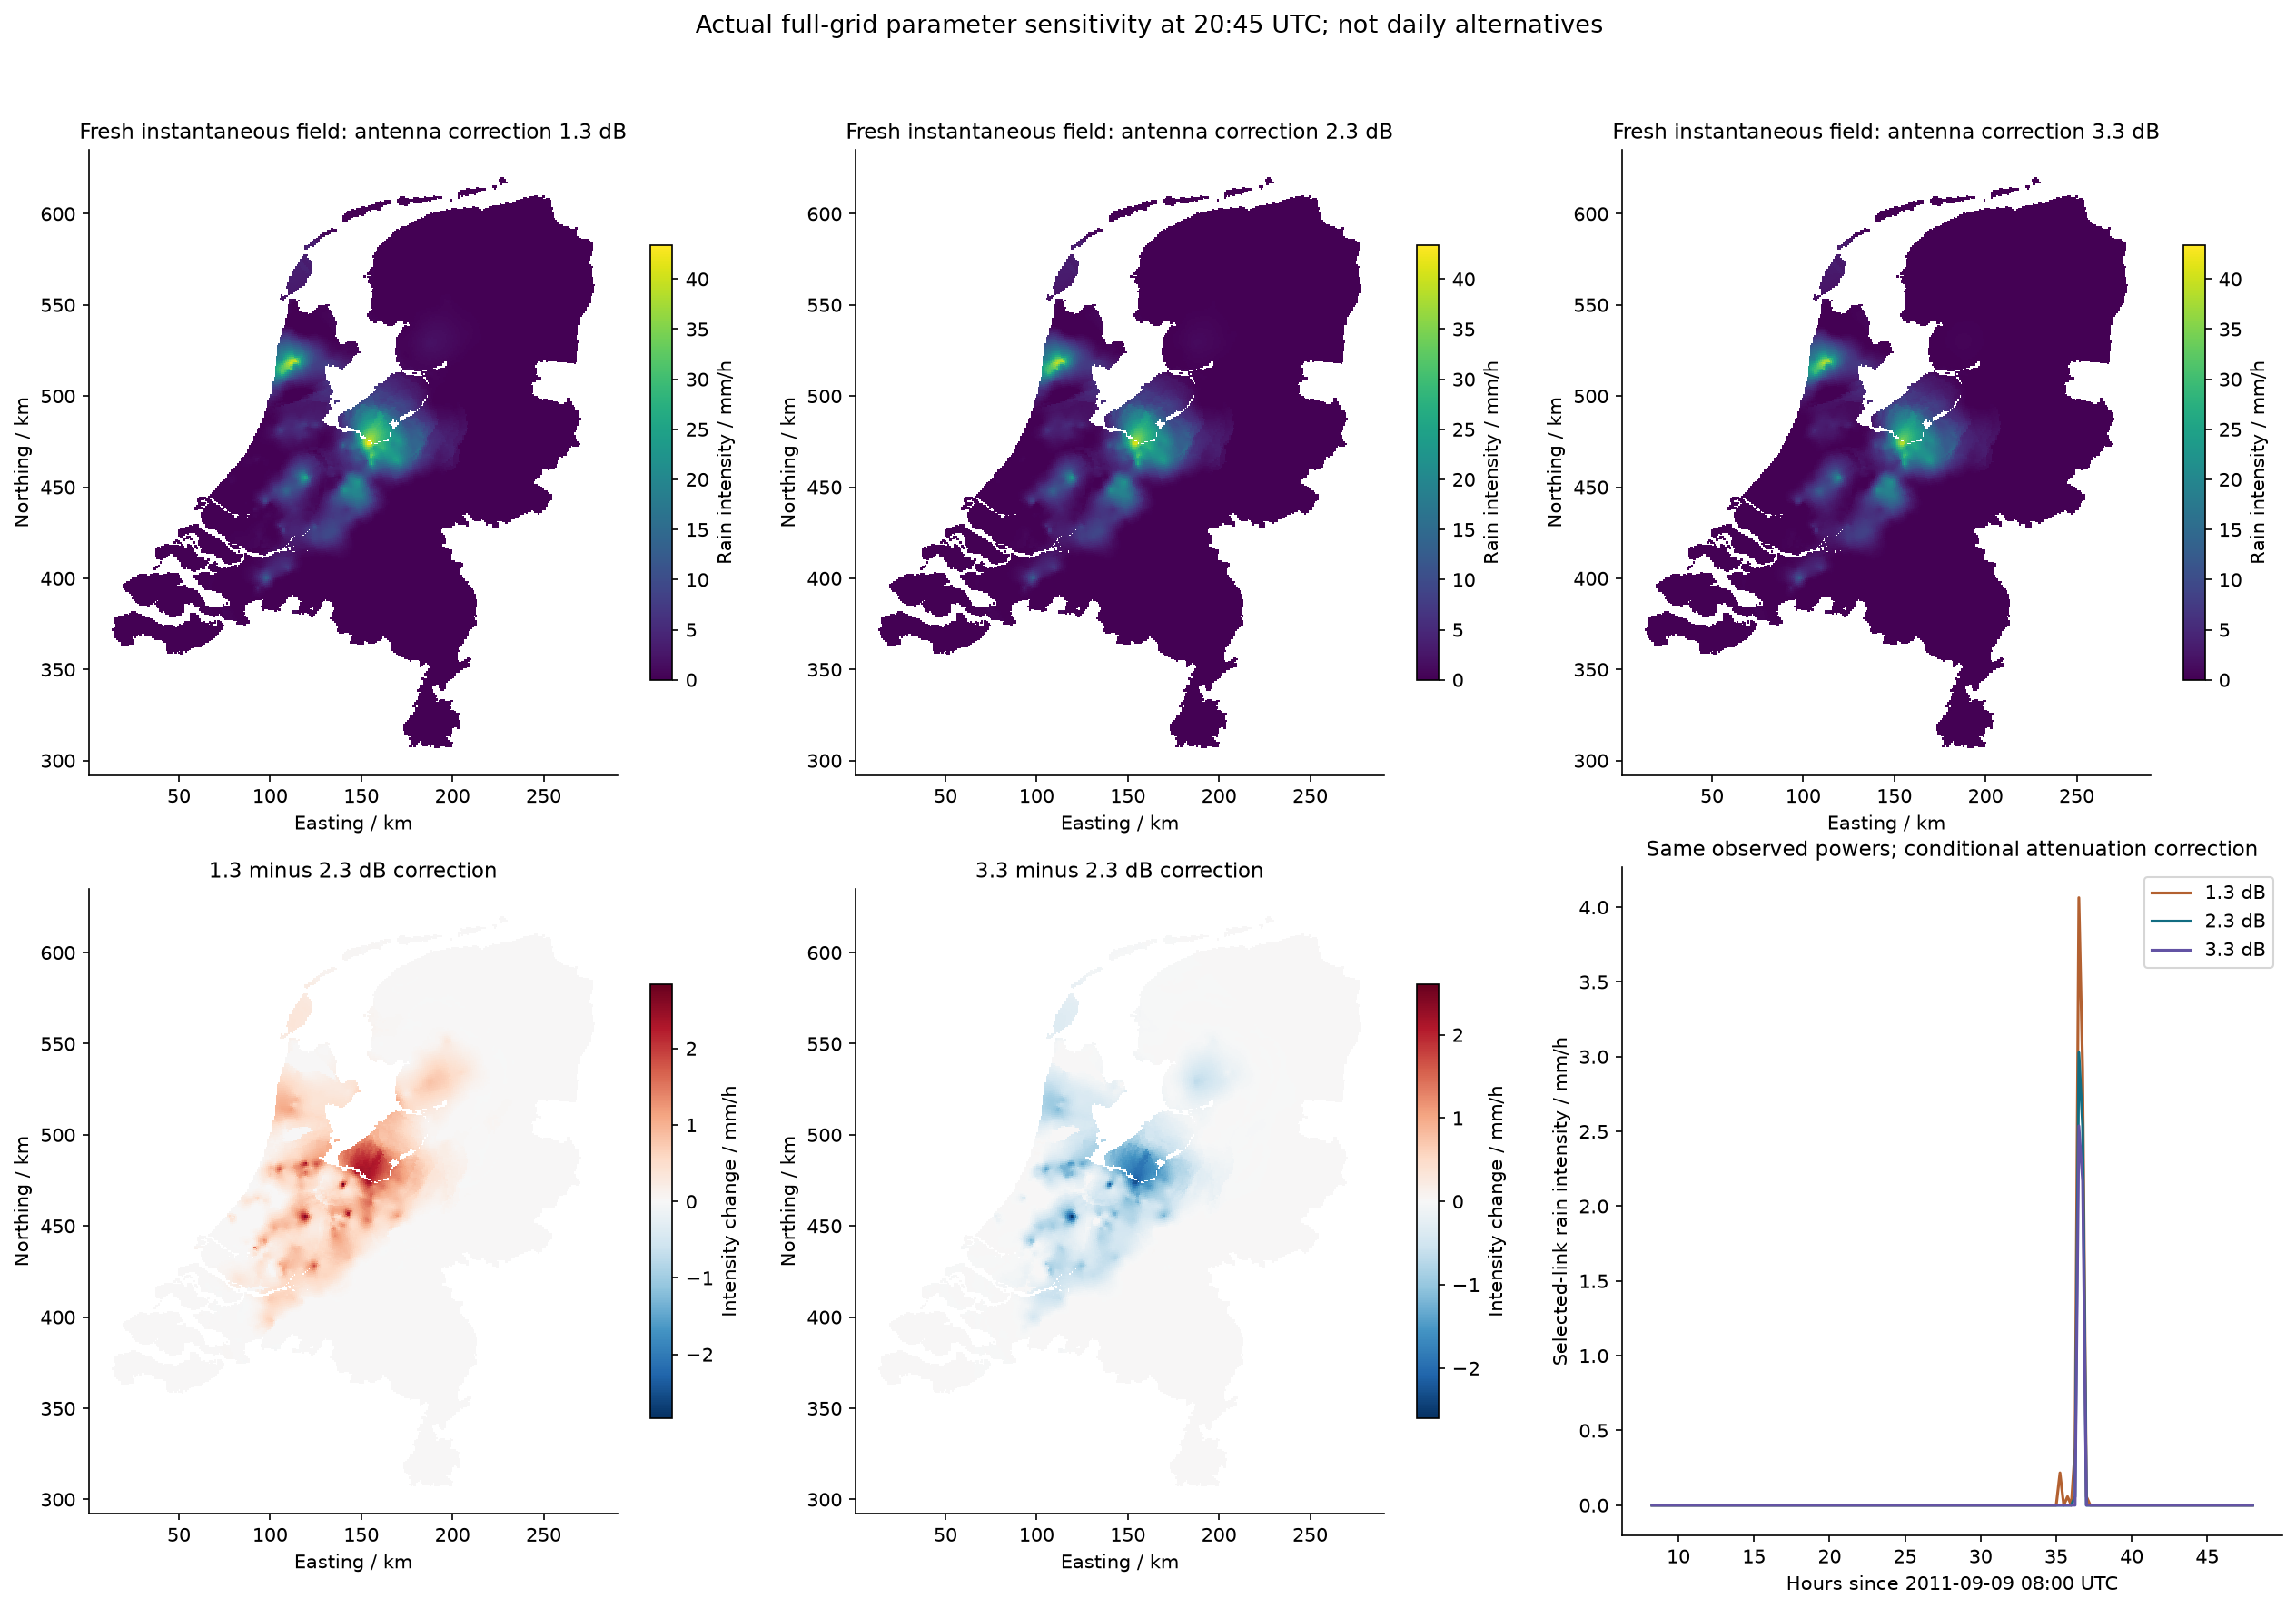

{'fresh_full_runtime_seconds': 761.162954600004, 'fresh_IDW_runtime_seconds': 237.47664159999113, 'judge': {'status': 'pass', 'passed': True, 'metrics': {'nrmse': 8.309475243871377e-15, 'negative_count': 0}, 'thresholds': {'nrmse': {'comparison': '<=', 'boundary': 9.663465651076436e-09}, 'negative_count': {'comparison': '<=', 'boundary': 0}}, 'errors': []}, 'daily_maximum_mm': 34.40845557364341, 'source_field_maxabs_mm': 5.965006266706041e-12, 'IDW_source_maxabs_mm': 2.4069635173873394e-11, 'sensitivity_timestamp': 201109102045, 'antenna_corrections_dB': [1.3, 2.3, 3.3], 'sensitivity_grid_means_mm_h': [1.8494407536842592, 1.6683353137540196, 1.5335850711157004], 'reference_role': 'Original method result, not independent rainfall truth'}


In [6]:
antenna_values=np.array([1.3,2.3,3.3]);sensitivity=[];link_sensitivity=[]
for aa in antenna_values:
 rain=rainfall_from_powers(data,stages['Pref'],stages['PminCor'],stages['PmaxCor'],raw['rain_coefficients'][0],antenna_db=float(aa))
 points,values=midpoint_observations(data,rain,geometry,stamp);sensitivity.append(interpolate(points,values,grid,stamp));link_sensitivity.append(rain[sel])
sensitivity=np.array(sensitivity);link_sensitivity=np.array(link_sensitivity)
fig,ax=plt.subplots(2,3,figsize=(17,12));colors=['#b36131','#126d82','#6353a4']
for a,field,aa in zip(ax[0],sensitivity,antenna_values):
 artist=map_panel(a,field,f'Fresh instantaneous field: antenna correction {aa:g} dB',maximum=sensitivity.max());fig.colorbar(artist,ax=a,shrink=.65,label='Rain intensity / mm/h')
for a,field,title in [(ax[1,0],sensitivity[0]-sensitivity[1],'1.3 minus 2.3 dB correction'),(ax[1,1],sensitivity[2]-sensitivity[1],'3.3 minus 2.3 dB correction')]:
 artist=map_panel(a,field,title,signed=True);fig.colorbar(artist,ax=a,shrink=.65,label='Intensity change / mm/h')
for aa,r,color in zip(antenna_values,link_sensitivity,colors):ax[1,2].plot(h,r,label=f'{aa:g} dB',color=color)
ax[1,2].set(xlabel='Hours since 2011-09-09 08:00 UTC',ylabel='Selected-link rain intensity / mm/h',title='Same observed powers; conditional attenuation correction');ax[1,2].legend()
save(fig,'figure6_sensitivity',dict(grid_xy=grid,antenna_correction_dB=antenna_values,instantaneous_mm_h=sensitivity,selected_link_mm_h=link_sensitivity,hours=h),'Actual full-grid parameter sensitivity at 20:45 UTC; not daily alternatives')
measurements=dict(fresh_full_runtime_seconds=runtime,fresh_IDW_runtime_seconds=idw_seconds,judge=report,daily_maximum_mm=float(x.max()),source_field_maxabs_mm=float(abs(x-y).max()),IDW_source_maxabs_mm=float(abs(idw-original['original_idw'][0]).max()),sensitivity_timestamp=stamp,antenna_corrections_dB=antenna_values.tolist(),sensitivity_grid_means_mm_h=sensitivity.mean(axis=1).tolist(),reference_role='Original method result, not independent rainfall truth')
(figdir/'notebook_measurements.json').write_text(json.dumps(measurements,indent=2,allow_nan=False));print(measurements)
